In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills.ipynb")

# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

https://github.com/fatiqnadeem/eds220-hwk3


- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

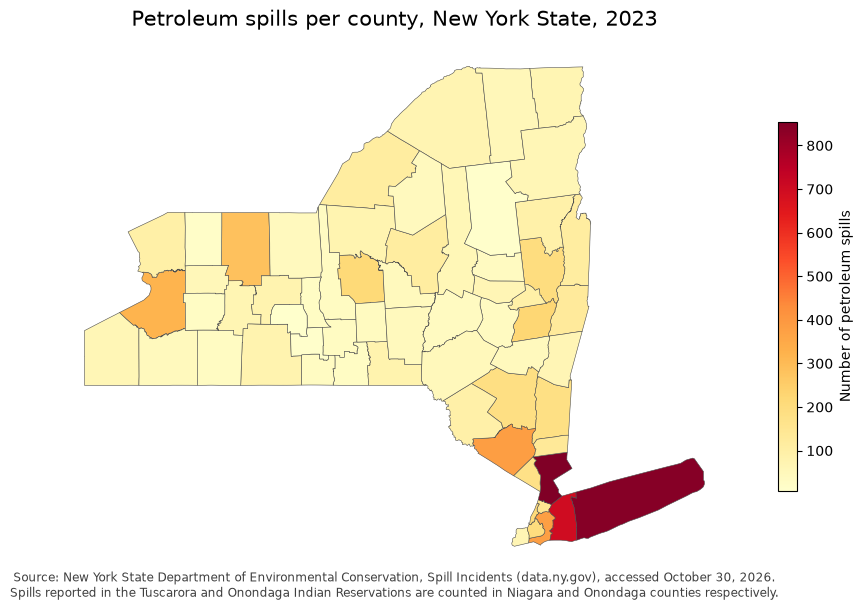

In [2]:
# FINAL CODE
import os
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

# ---- Spills: petroleum incidents in 2023, each spill number counted once per county ----
spills = pd.read_csv(os.path.join('data', 'Spill_Incidents_20261030.csv'),
                     dtype={'Spill Number': str})
spills.columns = spills.columns.str.lower().str.replace(' ', '_')
spills['spill_date'] = pd.to_datetime(spills['spill_date'], format='%m/%d/%Y')

spills_per_county = (spills[(spills['material_family'] == 'Petroleum')
                            & (spills['spill_date'].between('2023-01-01', '2023-12-31'))]
                     .groupby('county')['spill_number']
                     .nunique()
                     .reset_index(name='n_spills')
                     .replace({'county': {'St Lawrence': 'St. Lawrence'}}))   # Census spelling

# ---- Counties: New York polygons (state FIPS 36) with the join key named 'county' ----
ny_counties = (gpd.read_file(os.path.join('data', 'tl_2026_us_county', 'tl_2026_us_county.shp'))
                  .rename(columns=str.lower)
                  .query("statefp == '36'")
                  .rename(columns={'name': 'county'}))

# ---- Join, then fold each reservation's spills into the county that surrounds it ----
ny_spills = ny_counties.merge(spills_per_county, on='county', how='inner')

for reservation, county in {'Tuscarora Indian Reservation': 'Niagara',
                            'Onondaga Indian Reservation': 'Onondaga'}.items():
    ny_spills.loc[ny_spills['county'] == county, 'n_spills'] += (
        spills_per_county.loc[spills_per_county['county'] == reservation, 'n_spills'].item())

# ---- Choropleth ----
fig, ax = plt.subplots(figsize=(11, 8))

ny_spills.plot(column='n_spills',
               cmap='YlOrRd',
               edgecolor='0.3',
               linewidth=0.4,
               legend=True,
               legend_kwds={'label': 'Number of petroleum spills', 'shrink': 0.6},
               ax=ax)

ax.set_title('Petroleum spills per county, New York State, 2023', fontsize=15, pad=12)
ax.set_axis_off()
ax.annotate('Source: New York State Department of Environmental Conservation, Spill Incidents (data.ny.gov), '
            'accessed October 30, 2026.\nSpills reported in the Tuscarora and Onondaga Indian Reservations are '
            'counted in Niagara and Onondaga counties respectively.',
            xy=(0.5, 0.0), xycoords='axes fraction', ha='center', va='top', fontsize=8.5, color='0.25')

plt.show()

## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.

**Spill Incidents (New York State Department of Environmental Conservation).**
The first dataset is the NYSDEC Spill Incidents table published on the New York State open data portal
([data.ny.gov, dataset u44d-k5fk](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk)).
It records every spill of petroleum or other hazardous material reported to the Department under State law.
The portal posts updates daily and new spills typically appear within 72 hours of being reported, and the
Department states that records are entered as reported and are not field-verified. Each row holds one material reported for one spill incident, and the incident is identified by its
spill number, so an incident in which several materials were released occupies several rows. The 20 columns describe
the incident (spill number, program facility name, street, locality, county, ZIP code, SWIS code, DEC region),
its timing (spill date, received date, close date), its circumstances (contributing factor, waterbody, source), and the
material (material name, material family, quantity, units, recovered). The file I downloaded as a CSV export on
October 30, 2026 has 574,628 rows, with spill dates running from 1900 through October 27, 2026.

**TIGER/Line 2026 Counties and Equivalent Entities (U.S. Census Bureau).**
The second dataset is the 2026 release of the Census Bureau's TIGER/Line county shapefile
(`tl_2026_us_county.zip`, downloaded from the
[TIGER/Line 2026 page](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html)
on October 30, 2026). It holds one polygon for each of the 3,235 counties and county equivalents in the United States,
Puerto Rico and the Island Areas, with 18 attribute columns including the state and county FIPS codes (`STATEFP`,
`COUNTYFP`, `GEOID`), the county name (`NAME`) and its name with legal description (`NAMELSAD`), land and water area
(`ALAND`, `AWATER`) and an interior point. The geometries are in the NAD83 geographic coordinate system (EPSG:4269).

## 3. Import libraries

In [3]:
# Libraries for file paths, numerics, tabular data, plotting and vector geodata
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [4]:
# Spill numbers are identifiers with leading zeros, so read them as text
fp = os.path.join('data', 'Spill_Incidents_20261030.csv')
spills = pd.read_csv(fp, dtype={'Spill Number': str})

# TIGER/Line 2026 counties shapefile
fp = os.path.join('data', 'tl_2026_us_county', 'tl_2026_us_county.shp')
counties = gpd.read_file(fp)

<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

In [5]:
# a. First rows of the spills data
spills.head()

,Spill Number,Program Facility Name,Street 1,Street 2,Locality,County,ZIP Code,SWIS Code,DEC Region,Spill Date,Received Date,Contributing Factor,Waterbody,Source,Close Date,Material Name,Material Family,Quantity,Units,Recovered
0,0107132,MH 864,RT 119/MILLWOOD RD,NaN,ELMSFORD,Westchester,NaN,6000,3,10/10/2001,10/10/2001,Unknown,NaN,Unknown,10/15/2001,unknown material,Other,10.0,Gallons,0.0
1,0405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0.0,NaN,0.0
2,0405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0.0,Pounds,0.0
3,0204667,POLE 16091,GRACE AVE/BURKE AVE,NaN,BRONX,Bronx,NaN,301,2,08/02/2002,08/02/2002,Equipment Failure,NaN,Commercial/Industrial,10/28/2002,transformer oil,Petroleum,1.0,Gallons,0.0
4,0210559,POLE ON,FERDALE LOMIS RD / RT 52,NaN,LIBERTY,Sullivan,NaN,5336,3,01/20/2003,01/20/2003,Traffic Accident,NaN,Commercial/Industrial,01/22/2003,transformer oil,Petroleum,6.0,Gallons,6.0


In [6]:
# b. Data type of each column
spills.dtypes

Spill Number                 str
Program Facility Name        str
Street 1                     str
Street 2                     str
Locality                     str
County                       str
ZIP Code                     str
SWIS Code                  int64
DEC Region                 int64
Spill Date                   str
Received Date                str
Contributing Factor          str
Waterbody                    str
Source                       str
Close Date                   str
Material Name                str
Material Family              str
Quantity                 float64
Units                        str
Recovered                float64
dtype: object

In [7]:
# c. Material families recorded (column names are still the raw ones with capitals and spaces)
spills['Material Family'].unique()

<StringArray>
['Other', 'Petroleum', 'Hazardous Material', 'Oxygenates']
Length: 4, dtype: str

In [8]:
# d. Every distinct value of the county column
spills['County'].unique()

<StringArray>
[                            'Westchester',
                                  'Queens',
                                   'Bronx',
                                'Sullivan',
                                'Cortland',
                                'New York',
                                  'Ulster',
                                   'Kings',
                                  'Orange',
                                'Dutchess',
                                'Onondaga',
                                'Saratoga',
                                  'Cayuga',
                                  'Oswego',
                                  'Warren',
                                 'Niagara',
                                'Rockland',
                                  'Nassau',
                               'Jefferson',
                             'Schenectady',
                                  'Albany',
                                  'Monroe',
                  

In [9]:
# Dimensions of the full dataset and the number of distinct county labels
print(f"Rows and columns: {spills.shape}")
print(f"Distinct values in County: {spills['County'].nunique()}")

Rows and columns: (574628, 20)
Distinct values in County: 87


The spills table has 574,628 rows and 20 columns. The column names mix capital letters and spaces
(for example `Spill Number` and `Material Family`), so I will simplify them before working with the data.
`pandas` read the three date columns (`Spill Date`, `Received Date`, `Close Date`) as text in the form
`MM/DD/YYYY`, so they need to be converted to datetime before I can select a year. The `Material Family` column
takes only four values (Petroleum, Hazardous Material, Other and Oxygenates), which means the petroleum filter
in the next section is a simple equality test. The `County` column has 87 distinct labels, and they are not all
New York counties. It also contains DEC regions in neighbouring states and Canada (for example
`New Jersey - Region 2`), several Indian Reservations listed as their own jurisdiction, and `St Lawrence`
spelled without a period, all of which will matter when I match these names to the Census county names.

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [10]:
# Lower-case the column names and replace spaces with underscores
spills.columns = spills.columns.str.lower().str.replace(' ', '_')
spills.columns

Index(['spill_number', 'program_facility_name', 'street_1', 'street_2',
       'locality', 'county', 'zip_code', 'swis_code', 'dec_region',
       'spill_date', 'received_date', 'contributing_factor', 'waterbody',
       'source', 'close_date', 'material_name', 'material_family', 'quantity',
       'units', 'recovered'],
      dtype='str')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [11]:
# Convert the three date columns from MM/DD/YYYY text to datetime
for col in ['spill_date', 'received_date', 'close_date']:
    spills[col] = pd.to_datetime(spills[col], format='%m/%d/%Y')

spills.dtypes

spill_number                        str
program_facility_name               str
street_1                            str
street_2                            str
locality                            str
county                              str
zip_code                            str
swis_code                         int64
dec_region                        int64
spill_date               datetime64[us]
received_date            datetime64[us]
contributing_factor                 str
waterbody                           str
source                              str
close_date               datetime64[us]
material_name                       str
material_family                     str
quantity                        float64
units                               str
recovered                       float64
dtype: object

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [12]:
# Petroleum spills whose spill date falls in calendar year 2023 (between() is inclusive at both ends)
petr_23 = spills[(spills['material_family'] == 'Petroleum') & (spills['spill_date'].between('2023-01-01', '2023-12-31'))]

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [13]:
# Confirm the selection covers 2023 only and every month of that year
print(f"Years present in petr_23: {petr_23['spill_date'].dt.year.unique().tolist()}")
print(f"Months present in petr_23: {sorted(petr_23['spill_date'].dt.month.unique().tolist())}")
print(f"Earliest spill date: {petr_23['spill_date'].min().date()}, latest spill date: {petr_23['spill_date'].max().date()}")

Years present in petr_23: [2023]
Months present in petr_23: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Earliest spill date: 2023-01-01, latest spill date: 2023-12-31


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [14]:
# Every row must be petroleum, and petroleum must be the only material family present
assert (petr_23['material_family'] == 'Petroleum').all()
assert petr_23['material_family'].nunique() == 1
assert 'Petroleum' in petr_23['material_family'].unique()
print("All assert tests passed: petr_23 contains petroleum spills only.")

All assert tests passed: petr_23 contains petroleum spills only.


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

In [15]:
# Rows versus distinct spill numbers
print(f"Number of rows in petr_23: {len(petr_23)}")
print(f"Number of unique spills in petr_23: {petr_23['spill_number'].nunique()}")

Number of rows in petr_23: 8468
Number of unique spills in petr_23: 8228


In [16]:
# Look at one spill number that appears in more than one row
(petr_23[petr_23['spill_number'].duplicated(keep=False)]
     .sort_values('spill_number')
     [['spill_number', 'spill_date', 'county', 'material_name', 'quantity', 'units']]
     .head(6))

,spill_number,spill_date,county,material_name,quantity,units
105175,2208179,2023-01-04,Oswego,gasoline,0.0,NaN
107744,2208179,2023-01-04,Oswego,gasoline/ethanol,0.0,NaN
128924,2208234,2023-01-05,Dutchess,diesel,0.0,NaN
128925,2208234,2023-01-05,Dutchess,gasoline,0.0,NaN
144682,2208271,2023-01-08,Queens,unknown petroleum,2.0,Gallons
144695,2208271,2023-01-08,Queens,diesel,2.0,Gallons


The two numbers differ. `petr_23` has 8,468 rows but only 8,228 distinct spill numbers. A row in this
dataset describes one material reported for one incident rather than the incident itself, so a spill in
which several petroleum products were released, for example gasoline and diesel escaping from the same tank,
appears once per material under the same spill number. The table above shows this pattern, where consecutive
rows share a spill number, date and county and differ only in the material name. Counting rows would therefore
overstate the number of spills by about three percent, and in the next exercise I count distinct spill numbers
instead.

<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [17]:
# Distinct spill numbers per county, returned as a two-column dataframe with a fresh integer index
spills_per_county = (petr_23.groupby('county')['spill_number']
                            .nunique()
                            .reset_index(name='n_spills'))
spills_per_county

,county,n_spills
0,Albany,224
1,Allegany,32
2,Bronx,152
3,Broome,80
4,Cattaraugus,45
...,...,...
61,Washington,115
62,Wayne,41
63,Westchester,855
64,Wyoming,27


In [18]:
grader.check("q5d")

q5d results: All test cases passed!

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

In [19]:
# a. First rows of the counties geo-dataframe
counties.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,NaN,37340,NaN,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.613, -80.98674 28.61301..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,NaN,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10364 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,NaN,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,NaN,19700,NaN,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,NaN,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [20]:
# b. Data type of each column
counties.dtypes

STATEFP          str
COUNTYFP         str
COUNTYNS         str
GEOID            str
GEOIDFQ          str
NAME             str
NAMELSAD         str
LSAD             str
CLASSFP          str
MTFCC            str
CSAFP            str
CBSAFP           str
METDIVFP         str
FUNCSTAT         str
ALAND          int64
AWATER         int64
INTPTLAT         str
INTPTLON         str
geometry    geometry
dtype: object

In [21]:
# c. Coordinate reference system
counties.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

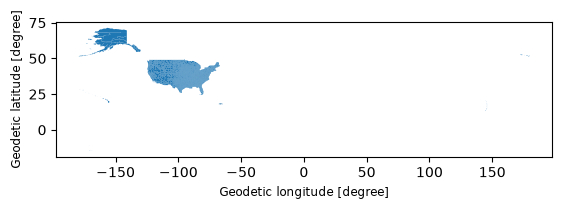

In [22]:
# d. Quick look at every polygon in the file
counties.plot()

The counties file is a `GeoDataFrame` with 3,235 rows and 19 columns, one row per county or county
equivalent. The identifier columns (`STATEFP`, `COUNTYFP`, `GEOID`) are stored as text, which preserves
their leading zeros, so selecting a state means comparing against a string such as `'36'` rather than an
integer. `NAME` holds the plain county name and `NAMELSAD` adds the legal description (for example
"Albany County"), while `ALAND` and `AWATER` are integer areas in square metres. The CRS is EPSG:4269,
the NAD83 geographic system in degrees of latitude and longitude, so the data are unprojected. The plot
shows the whole country together with Alaska, Hawaii, Puerto Rico and the Pacific islands, with Alaska's
Aleutian chain stretching across the antimeridian, which is why the map looks compressed and why I need to
select New York before plotting anything useful.

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

In [23]:
# Lower-case the column names
counties.columns = counties.columns.str.lower()
counties.columns

Index(['statefp', 'countyfp', 'countyns', 'geoid', 'geoidfq', 'name',
       'namelsad', 'lsad', 'classfp', 'mtfcc', 'csafp', 'cbsafp', 'metdivfp',
       'funcstat', 'aland', 'awater', 'intptlat', 'intptlon', 'geometry'],
      dtype='str')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

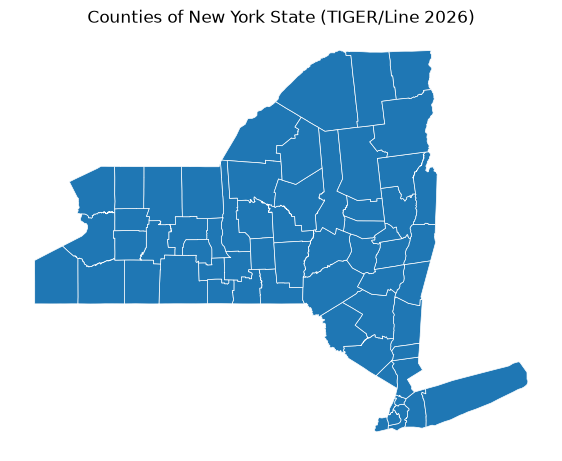

In [24]:
# New York State has FIPS code 36; statefp is text, so compare with a string
ny_counties = counties[counties['statefp'] == '36']

fig, ax = plt.subplots(figsize=(7, 6))
ny_counties.plot(ax=ax, edgecolor='white', linewidth=0.5)
ax.set_title('Counties of New York State (TIGER/Line 2026)')
ax.set_axis_off()
plt.show()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


In [25]:
# a. County names in the Census data, each once
print(sorted(ny_counties['name'].unique()))

['Albany', 'Allegany', 'Bronx', 'Broome', 'Cattaraugus', 'Cayuga', 'Chautauqua', 'Chemung', 'Chenango', 'Clinton', 'Columbia', 'Cortland', 'Delaware', 'Dutchess', 'Erie', 'Essex', 'Franklin', 'Fulton', 'Genesee', 'Greene', 'Hamilton', 'Herkimer', 'Jefferson', 'Kings', 'Lewis', 'Livingston', 'Madison', 'Monroe', 'Montgomery', 'Nassau', 'New York', 'Niagara', 'Oneida', 'Onondaga', 'Ontario', 'Orange', 'Orleans', 'Oswego', 'Otsego', 'Putnam', 'Queens', 'Rensselaer', 'Richmond', 'Rockland', 'Saratoga', 'Schenectady', 'Schoharie', 'Schuyler', 'Seneca', 'St. Lawrence', 'Steuben', 'Suffolk', 'Sullivan', 'Tioga', 'Tompkins', 'Ulster', 'Warren', 'Washington', 'Wayne', 'Westchester', 'Wyoming', 'Yates']


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

In [26]:
# b. County labels in the spills data, each once
print(sorted(spills_per_county['county'].unique()))

['Albany', 'Allegany', 'Bronx', 'Broome', 'Cattaraugus', 'Cayuga', 'Chautauqua', 'Chemung', 'Chenango', 'Clinton', 'Columbia', 'Cortland', 'Delaware', 'Dutchess', 'Erie', 'Essex', 'Franklin', 'Fulton', 'Genesee', 'Greene', 'Hamilton', 'Herkimer', 'Jefferson', 'Kings', 'Lewis', 'Livingston', 'Madison', 'Monroe', 'Montgomery', 'Nassau', 'New Jersey - Region 2', 'New York', 'Niagara', 'Oneida', 'Onondaga', 'Onondaga Indian Reservation', 'Ontario', 'Orange', 'Orleans', 'Oswego', 'Otsego', 'Pennsylvania - Region 3', 'Putnam', 'Queens', 'Rensselaer', 'Richmond', 'Rockland', 'Saratoga', 'Schenectady', 'Schoharie', 'Schuyler', 'Seneca', 'St Lawrence', 'Steuben', 'Suffolk', 'Sullivan', 'Tioga', 'Tompkins', 'Tuscarora Indian Reservation', 'Ulster', 'Warren', 'Washington', 'Wayne', 'Westchester', 'Wyoming', 'Yates']


<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [27]:
# c. Labels in spills_per_county that have no match in ny_counties
diff_names_spills = list(np.setdiff1d(spills_per_county['county'].unique(), ny_counties['name'].unique()))
diff_names_spills

['New Jersey - Region 2',
 'Onondaga Indian Reservation',
 'Pennsylvania - Region 3',
 'St Lawrence',
 'Tuscarora Indian Reservation']

In [28]:
grader.check("7Ac")

7Ac results: All test cases passed!

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [29]:
# d. Names in ny_counties that have no match in spills_per_county
diff_names_ny = list(np.setdiff1d(ny_counties['name'].unique(), spills_per_county['county'].unique()))
diff_names_ny

['St. Lawrence']

In [30]:
grader.check("7Ad")

7Ad results: All test cases passed!

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?


In [31]:
# e. Spills recorded in the two reservations
spills_per_county[spills_per_county['county'].isin(['Tuscarora Indian Reservation',
                                                     'Onondaga Indian Reservation'])]

,county,n_spills
35,Onondaga Indian Reservation,1
58,Tuscarora Indian Reservation,2


### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


In [32]:
# Match the Census spelling of St. Lawrence
spills_per_county.loc[spills_per_county['county'] == 'St Lawrence', 'county'] = 'St. Lawrence'

assert 'St. Lawrence' in spills_per_county['county'].values
assert 'St Lawrence' not in spills_per_county['county'].values
print("Update verified: St. Lawrence now matches the spelling in ny_counties.")

Update verified: St. Lawrence now matches the spelling in ny_counties.


### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


In [33]:
# a. Give the join key the same name in both dataframes
ny_counties = ny_counties.rename(columns={'name': 'county'})
ny_counties.columns

Index(['statefp', 'countyfp', 'countyns', 'geoid', 'geoidfq', 'county',
       'namelsad', 'lsad', 'classfp', 'mtfcc', 'csafp', 'cbsafp', 'metdivfp',
       'funcstat', 'aland', 'awater', 'intptlat', 'intptlon', 'geometry'],
      dtype='str')

b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


In [34]:
# b. Inner join on county name (merge on the GeoDataFrame so the result keeps its geometry)
ny_spills = ny_counties.merge(spills_per_county, on='county', how='inner')

print(f"ny_spills is a {type(ny_spills).__name__} with {ny_spills.shape[0]} rows and {ny_spills.shape[1]} columns")
ny_spills.head()

ny_spills is a GeoDataFrame with 62 rows and 20 columns


,statefp,countyfp,countyns,geoid,geoidfq,county,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry,n_spills
0,36,029,00974113,36029,0500000US36029,Erie,Erie County,06,H1,G4020,160,15380,NaN,A,2700743371,476876406,+42.7527590,-078.7781922,"POLYGON ((-78.7776 42.46188, -78.77756 42.4617...",320
1,36,063,00974130,36063,0500000US36063,Niagara,Niagara County,06,H1,G4020,160,15380,NaN,A,1352876142,1598772310,+43.2726719,-078.8129431,"POLYGON ((-78.49165 43.08396, -78.49179 43.084...",97
2,36,045,00974121,36045,0500000US36045,Jefferson,Jefferson County,06,H1,G4020,NaN,48060,NaN,A,3283928401,1524534721,+43.9963890,-076.0529678,"POLYGON ((-75.90417 43.69796, -75.90437 43.697...",114
3,36,101,00974148,36101,0500000US36101,Steuben,Steuben County,06,H1,G4020,236,18500,NaN,A,3601403364,35034920,+42.2667252,-077.3855253,"POLYGON ((-77.08327 42.00002, -77.09391 41.999...",77
4,36,099,00974147,36099,0500000US36099,Seneca,Seneca County,06,H1,G4020,464,42900,NaN,A,838377561,172813845,+42.7822943,-076.8270880,"POLYGON ((-76.96393 43.01284, -76.96393 43.012...",27


<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

In [35]:
# c. Records of spills_per_county whose county has no polygon in ny_counties
dropped = spills_per_county[~spills_per_county['county'].isin(ny_spills['county'])]

print(f"The inner join dropped {len(dropped)} records holding {dropped['n_spills'].sum()} spills "
      f"out of {spills_per_county['n_spills'].sum()}.")
dropped

The inner join dropped 4 records holding 11 spills out of 8228.


,county,n_spills
30,New Jersey - Region 2,7
35,Onondaga Indian Reservation,1
41,Pennsylvania - Region 3,1
58,Tuscarora Indian Reservation,2


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

The join dropped four records that together hold 11 of the 8,228 petroleum spills, which is about 0.13
percent of the total, so the overall picture on the map does not change. The records behave differently,
however. The two labelled `New Jersey - Region 2` and `Pennsylvania - Region 3` (8 spills) describe
incidents outside New York that the DEC handled through its regional offices, so they have no New York county
to belong to and excluding them from a map of New York State is the correct treatment. The two reservation
records (3 spills) describe incidents that took place inside New York's borders, on the Tuscarora and Onondaga
Nations' lands, so dropping them would silently remove real New York spills from the map and understate
Niagara and Onondaga counties by 2 and 1 spills. At the scale of those counties (97 and 214 spills) the
difference is invisible in the colour scale, but it is a loss of information rather than an error in the
source, so I add those spills back in the next exercise and disclose that choice on the map.

<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

In [36]:
# e. Fold each reservation's spills into the county that surrounds it
reservation_to_county = {'Tuscarora Indian Reservation': 'Niagara',
                         'Onondaga Indian Reservation': 'Onondaga'}

for reservation, county in reservation_to_county.items():
    n_reservation = spills_per_county.loc[spills_per_county['county'] == reservation, 'n_spills'].item()
    ny_spills.loc[ny_spills['county'] == county, 'n_spills'] += n_reservation

In [37]:
# Verify: each updated county now equals its own count plus the reservation count in spills_per_county
for reservation, county in reservation_to_county.items():
    expected = spills_per_county.loc[spills_per_county['county'].isin([county, reservation]), 'n_spills'].sum()
    assert ny_spills.loc[ny_spills['county'] == county, 'n_spills'].item() == expected

print(f"Spills on the map: {ny_spills['n_spills'].sum()} "
      f"(all 2023 petroleum spills except the {dropped.loc[~dropped['county'].isin(reservation_to_county), 'n_spills'].sum()} outside New York)")
ny_spills.loc[ny_spills['county'].isin(reservation_to_county.values()), ['county', 'n_spills']]

Spills on the map: 8220 (all 2023 petroleum spills except the 8 outside New York)


,county,n_spills
1,Niagara,99
19,Onondaga,215


## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



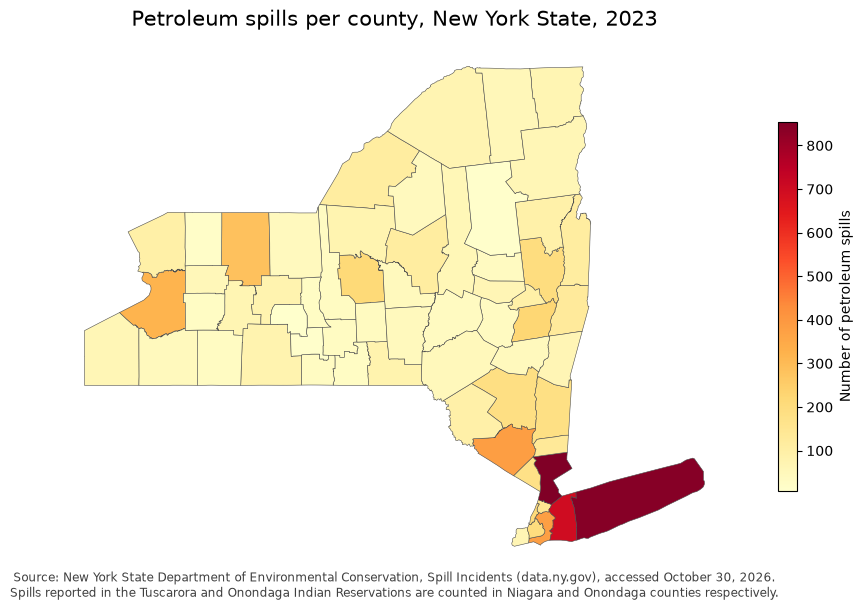

In [38]:
fig, ax = plt.subplots(figsize=(11, 8))

ny_spills.plot(column='n_spills',
               cmap='YlOrRd',
               edgecolor='0.3',
               linewidth=0.4,
               legend=True,
               legend_kwds={'label': 'Number of petroleum spills', 'shrink': 0.6},
               ax=ax)

ax.set_title('Petroleum spills per county, New York State, 2023', fontsize=15, pad=12)
ax.set_axis_off()
ax.annotate('Source: New York State Department of Environmental Conservation, Spill Incidents (data.ny.gov), '
            'accessed October 30, 2026.\nSpills reported in the Tuscarora and Onondaga Indian Reservations are '
            'counted in Niagara and Onondaga counties respectively.',
            xy=(0.5, 0.0), xycoords='axes fraction', ha='center', va='top', fontsize=8.5, color='0.25')

plt.show()

b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.

In [39]:
# Counties with the most and the fewest petroleum spills in 2023, to support the description below
print("Five counties with the most spills:")
print(ny_spills.nlargest(5, 'n_spills')[['county', 'n_spills']].to_string(index=False))
print("\nFive counties with the fewest spills:")
print(ny_spills.nsmallest(5, 'n_spills')[['county', 'n_spills']].to_string(index=False))
print(f"\nMedian county: {ny_spills['n_spills'].median():.0f} spills")

Five counties with the most spills:
     county  n_spills
Westchester       855
    Suffolk       845
     Nassau       698
     Orange       382
     Queens       380

Five counties with the fewest spills:
  county  n_spills
   Yates         7
Hamilton        12
Schuyler        13
 Orleans        19
  Seneca        27

Median county: 68 spills


**How the map was created.** I started from the NYSDEC Spill Incidents table, simplified its column names,
converted the dates to datetime, and kept the rows whose material family is petroleum and whose spill date
falls in 2023. Since the table holds one row per material rather than per incident, I counted distinct spill
numbers within each county, which gives 8,228 spills across 66 county labels. On the Census side I selected
the 62 New York polygons from the 2026 TIGER/Line county file using the state FIPS code and lower-cased the
column names. The two sources disagreed on one spelling (`St Lawrence` against `St. Lawrence`), which I fixed
in the spills table, and the spills table carried four labels with no county polygon, two out-of-state DEC
regions that I left out and two Indian Reservations whose spills I added to the surrounding counties. An
inner join on the county name attached the counts to the geometries, and I drew a choropleth with a
sequential yellow-to-red colour map, a colour bar labelled with the number of spills, a title, no axes, and
an annotation giving the data source, the access date and the treatment of the reservation spills.

**Key takeaways.** Petroleum spills in 2023 concentrate in the downstate counties around New York City.
Westchester (855) and Suffolk (845) lead by a wide margin, followed by Nassau (698), Orange (382) and Queens
(380), so the Hudson Valley and Long Island together account for a large share of the state's reported
incidents. The three most urban boroughs do not top the list, since New York County (206) and Kings (200) sit
well below the suburban counties that ring the city, which suggests that reported petroleum spills follow the
distribution of vehicles, heating-oil tanks and fuel storage rather than population density alone. Upstate,
the counties with mid-sized cities (Erie with 320, Monroe with 285, Onondaga with 215 after the reservation
adjustment and Albany with 224) form a second tier, while the rural counties of the Adirondacks and the
Southern Tier report the fewest incidents, with Yates (7), Hamilton (12) and Schuyler (13) at the bottom.
The median county recorded 68 spills, so the colour scale is dominated by a handful of high-count counties
and most of the state sits in the lightest two shades.

**Data governance and the CARE principles.** The NYSDEC records the Tuscarora and Onondaga Indian
Reservations as jurisdictions in their own right, separate from the counties that surround them. For the
purpose of a county choropleth I folded their three spills into Niagara and Onondaga counties, which keeps the
statewide count complete and changes neither county's colour, but it also removes the two Nations from the
map and assigns data about incidents on their land to governments that hold no authority there. Read against
the CARE principles from Task 1, that choice serves the analyst's convenience more than the communities. The
principle of Authority to Control holds that Indigenous nations have the right to govern how data about their
lands and peoples are represented, and I made this decision without any input from the Tuscarora Nation or
the Onondaga Nation. The principle of Responsibility would ask me at minimum to disclose the choice, which the
annotation on the map does, and a more careful workflow would represent the reservations as their own units
using the Census Bureau's American Indian areas file, or would ask the Nations how, and whether, incidents on
their lands should appear in a public map. The principle of Ethics also cuts the other way, since with only
one and two spills a separately coloured reservation polygon could make individual incidents identifiable, so
aggregation can protect as well as erase. The honest summary is that the map is accurate at the county level,
that the absorption of the reservation spills is a documented analytical convenience rather than a governance
decision, and that a CARE-aligned version of this analysis would begin by consulting the communities whose
land the data describe.

## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.

---

To double-check your work, the cell below will rerun all of the autograder tests.

In [40]:
grader.check_all()

7Ac results: All test cases passed!

7Ad results: All test cases passed!

q5d results: All test cases passed!